# 05 — Seeded Region Growing (SRG)

SRG phát triển nhiều vùng đồng thời và kết nạp pixel biên theo độ tương phản `delta` nhỏ nhất bằng min-heap.

Trong bộ cài đặt này, `delta` được dùng như độ chênh không âm `|I(x)-mean(A_i)|` (ảnh màu dùng chuẩn L2). Khi một pixel kề nhiều vùng, nó được gán cho vùng có delta nhỏ nhất. `boundary_mask` đánh dấu hai phía của các ranh giới nhãn trong kết quả cuối.

Hai tùy chọn quan trọng:
- `stale='lazy'`: khi lấy pixel khỏi heap, tính lại delta theo mean hiện tại; nếu đổi thì cập nhật và đẩy lại vào heap.
- `stale='frozen'`: dùng giá trị seed ban đầu làm tham chiếu nên điểm ưu tiên không đổi theo mean vùng.

Tie-breaking: `insertion`, `raster`, `random` (random tái lập được với `random_state`).

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import matplotlib.pyplot as plt
from cv_bt2.corner import *
from cv_bt2.data.synthetic import *
from cv_bt2.visualization import plot_corners, plot_labels

OUT = ROOT / "outputs" / "figures"
OUT.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

from cv_bt2.segmentation import (srg,srg_step_frames,seed_sensitivity,region_growing_classic)
from cv_bt2.segmentation.metrics import (count_regions,check_full_partition,check_region_count,partition_difference)
from cv_bt2.data.synthetic import gradient_scene,flat_scene,diagonal_scene

Project root: /mnt/data/Computer_Vision_BT2


## 1. Kiểm chứng các tính chất cơ bản

Yêu cầu: mọi pixel được gán nhãn, số vùng bằng số seed. Kiểm tra thêm khi đảo thứ tự seed; đây là kết quả thực nghiệm trên ảnh/cấu hình đang xét, không phải bảo đảm cho mọi ảnh và mọi quy tắc tie.

Full partition: True
Region count: 3 | số seed: 3 | đạt: True
Pixel khác sau đảo thứ tự seed và ánh xạ ID trở lại: 0


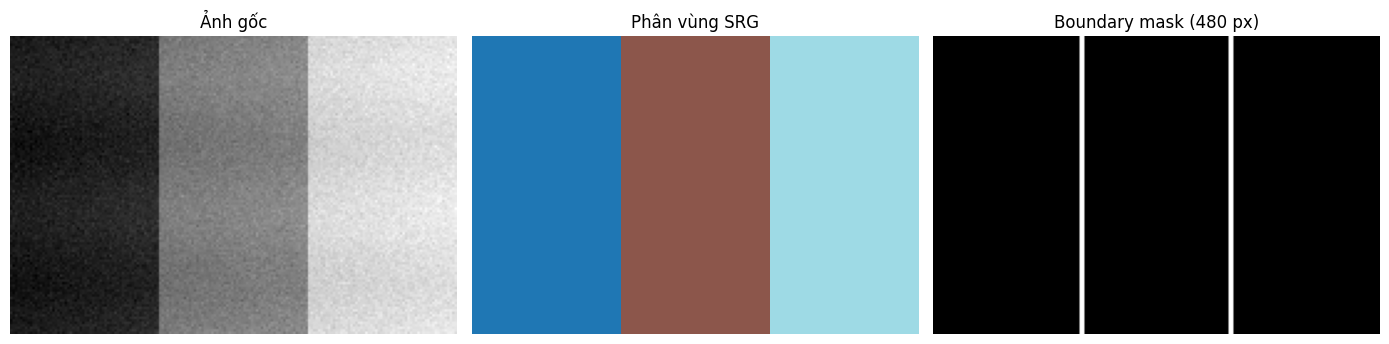

In [2]:
img=segmentation_scene(size=(120,180),random_state=42,noise=5)
seeds=[(60,20),(60,90),(60,160)]
labels,boundary=srg(img,seeds,connectivity=4,stale="lazy",tie="insertion")
reversed_labels,_=srg(img,list(reversed(seeds)),connectivity=4,stale="lazy",tie="insertion")
reversed_mapped=(len(seeds)-1)-reversed_labels
print("Full partition:",check_full_partition(labels))
print("Region count:",count_regions(labels),"| số seed:",len(seeds),"| đạt:",check_region_count(labels,seeds))
print("Pixel khác sau đảo thứ tự seed và ánh xạ ID trở lại:",int(np.count_nonzero(labels!=reversed_mapped)))
fig,ax=plt.subplots(1,3,figsize=(14,4))
ax[0].imshow(img,cmap="gray"); ax[0].set_title("Ảnh gốc"); ax[0].axis("off")
plot_labels(labels,ax=ax[1],title="Phân vùng SRG")
ax[2].imshow(boundary,cmap="gray"); ax[2].set_title(f"Boundary mask ({boundary.sum()} px)"); ax[2].axis("off")
plt.tight_layout(); plt.show()

## 2. Quá trình phát triển vùng

` srg_step_frames ` lưu ảnh nhãn ở các mốc tiến trình. Frame cuối phải trùng kết quả `srg()` chạy độc lập.

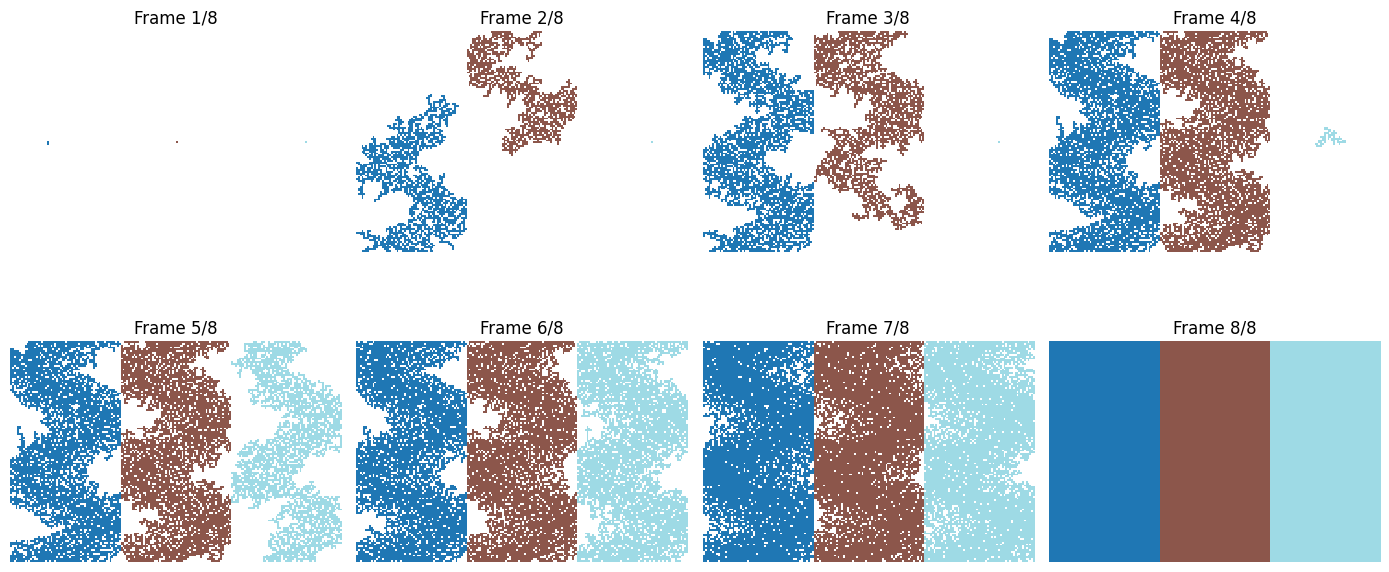

Số frame: 8 | frame cuối trùng srg(): True


In [3]:
frames=srg_step_frames(img,seeds,n_frames=8,connectivity=4,stale="lazy",tie="insertion")
fig,axes=plt.subplots(2,4,figsize=(14,7))
for i,(ax,frame) in enumerate(zip(axes.flat,frames),1):
    plot_labels(frame,ax=ax,title=f"Frame {i}/{len(frames)}")
plt.tight_layout(); plt.show()
print("Số frame:",len(frames),"| frame cuối trùng srg():",np.array_equal(frames[-1],labels))

## 3. So sánh Lazy và Frozen trên gradient

Gradient làm trung bình của mỗi vùng thay đổi khi vùng phát triển. Lazy cập nhật delta theo mean mới; Frozen tiếp tục đo từ seed gốc. Vì vậy hai biến thể có thể lấy pixel theo thứ tự khác nhau.

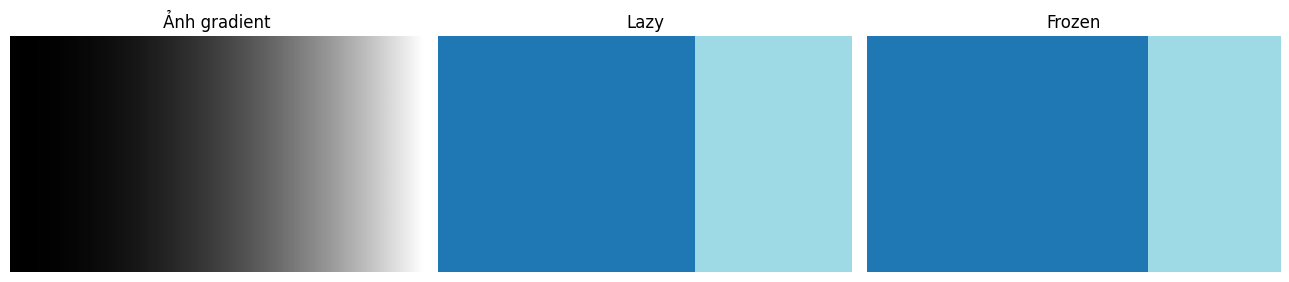

So sánh Lazy/Frozen: {'common_labeled_pixels': 11200, 'different_partition_pixels': 640, 'different_percent_of_common': 5.714285714285714, 'unassigned_a': 0, 'unassigned_b': 0}


In [4]:
grad=gradient_scene((80,140),nonlinear=True)
grad_seeds=[(40,5),(40,134)]
lab_lazy,_=srg(grad,grad_seeds,stale="lazy",tie="insertion")
lab_frozen,_=srg(grad,grad_seeds,stale="frozen",tie="insertion")
diff_stale=partition_difference(lab_lazy,lab_frozen)
fig,ax=plt.subplots(1,3,figsize=(13,4))
ax[0].imshow(grad,cmap="gray"); ax[0].set_title("Ảnh gradient"); ax[0].axis("off")
plot_labels(lab_lazy,ax=ax[1],title="Lazy")
plot_labels(lab_frozen,ax=ax[2],title="Frozen")
plt.tight_layout(); plt.show()
print("So sánh Lazy/Frozen:",diff_stale)

## 4. Tie-breaking trên ảnh phẳng

Ảnh phẳng có cùng cường độ ở mọi pixel nên mọi delta đều bằng nhau. Do đó kết quả phản ánh trực tiếp cách phá hòa trong heap.

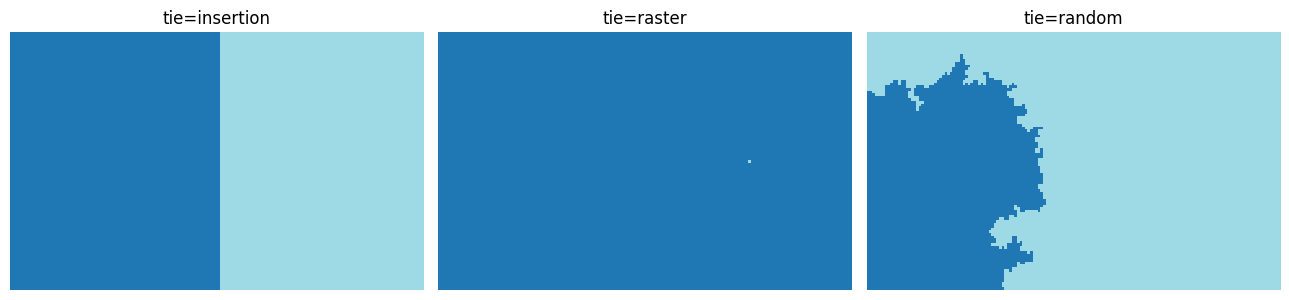

insertion vs raster : 7899 pixel khác
insertion vs random : 3278 pixel khác
raster vs random : 11177 pixel khác


In [5]:
flat=flat_scene((100,160),value=128)
flat_seeds=[(50,40),(50,120)]
tie_results={}
for method in ["insertion","raster","random"]:
    tie_results[method],_=srg(flat,flat_seeds,connectivity=4,stale="lazy",tie=method,random_state=42)
fig,ax=plt.subplots(1,3,figsize=(13,4))
for a,method in zip(ax,tie_results):
    plot_labels(tie_results[method],ax=a,title=f"tie={method}")
plt.tight_layout(); plt.show()
for first,second in [("insertion","raster"),("insertion","random"),("raster","random")]:
    print(first,"vs",second,":",int(np.count_nonzero(tie_results[first]!=tie_results[second])),"pixel khác")

## 5. Connectivity 4 và 8

Connectivity 4 xét trên/dưới/trái/phải. Connectivity 8 bổ sung bốn pixel chéo. Sự thay đổi lân cận có thể làm thay đổi thứ tự phát triển và vị trí đường biên.

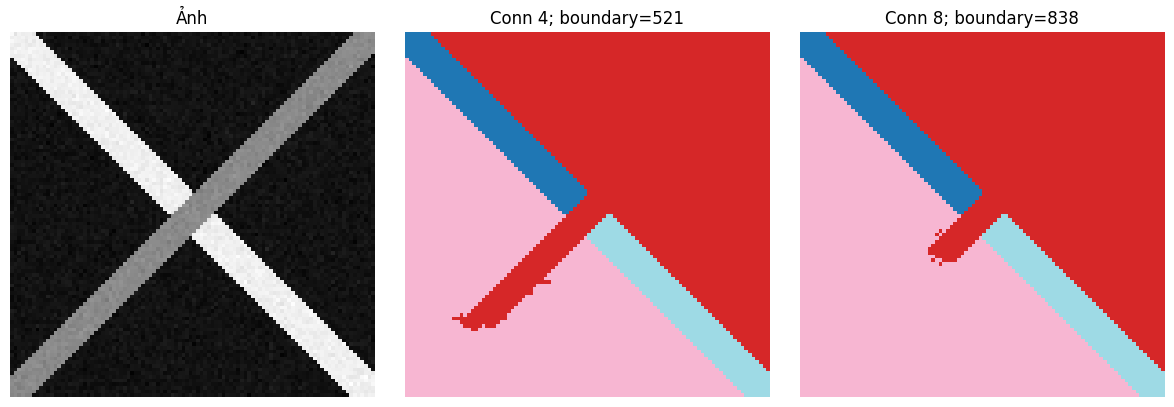

Pixel khác nhãn giữa conn4 và conn8: 218


In [6]:
diag=diagonal_scene((100,100))
diag_seeds=[(15,15),(15,85),(85,15),(85,85)]
lab4,b4=srg(diag,diag_seeds,connectivity=4)
lab8,b8=srg(diag,diag_seeds,connectivity=8)
fig,ax=plt.subplots(1,3,figsize=(12,4))
ax[0].imshow(diag,cmap="gray"); ax[0].set_title("Ảnh"); ax[0].axis("off")
plot_labels(lab4,ax=ax[1],title=f"Conn 4; boundary={b4.sum()}")
plot_labels(lab8,ax=ax[2],title=f"Conn 8; boundary={b8.sum()}")
plt.tight_layout(); plt.show()
print("Pixel khác nhãn giữa conn4 và conn8:",int(np.count_nonzero(lab4!=lab8)))

## 6. Seed sensitivity

Dịch seed ngẫu nhiên trong phạm vi `±jitter` pixel nhiều lần. Bản đồ kết quả lưu tần suất một pixel đổi nhãn so với phân vùng baseline, không cần ground truth. Giá trị 0 nghĩa là không đổi trong các lần thử; giá trị gần 1 nghĩa là thay đổi thường xuyên.

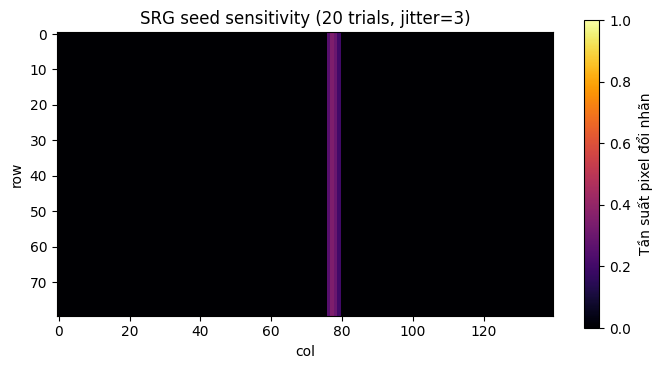

Pixel bị ảnh hưởng: 2.86 %
Tần suất trung bình: 0.0079 | max: 0.35


In [7]:
sensitivity_img=gradient_scene((80,140),nonlinear=True)
sensitivity_seeds=[(40,20),(40,120)]
frequency=seed_sensitivity(
    sensitivity_img,sensitivity_seeds,
    lambda image,seed_list: srg(image,seed_list,stale="lazy",tie="insertion"),
    n_trials=20,jitter=3,random_state=42)
plt.figure(figsize=(8,4)); plt.imshow(frequency,cmap="inferno",vmin=0,vmax=1)
plt.colorbar(label="Tần suất pixel đổi nhãn"); plt.title("SRG seed sensitivity (20 trials, jitter=3)")
plt.xlabel("col"); plt.ylabel("row"); plt.show()
print("Pixel bị ảnh hưởng:",round(100*np.mean(frequency>0),2),"%")
print("Tần suất trung bình:",round(float(frequency.mean()),4),"| max:",round(float(frequency.max()),3))

## 7. Tổng kết quy trình heap

1. Tìm pixel chưa gán nhãn kề ít nhất một vùng đã phát triển.
2. Tính delta tới trung bình (Lazy) hoặc giá trị seed (Frozen).
3. Đưa ứng viên vào min-heap; delta nhỏ được ưu tiên.
4. Khi pop, bỏ entry cũ/đã gán. Lazy tính lại delta; entry cũ được cập nhật và đẩy lại heap nếu giá trị ưu tiên thay đổi.
5. Gán pixel vào vùng có delta nhỏ nhất; cập nhật tổng và số pixel của vùng.
6. Đưa các lân cận mới vào heap; dừng khi toàn bộ ảnh được gán nhãn.

**Giới hạn cần nêu:** tie-breaking và thứ tự cập nhật có thể làm kết quả phụ thuộc thứ tự xử lý, vì vậy không tuyên bố tính bất biến seed-order tuyệt đối cho mọi ảnh.